# Снижение активности по картам: кто, насколько и за счёт чего

**Автор: Ёщик Юлия Андреевна**

**Период данных:** 2024-01-01 — 2025-06-30

**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, HTML
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 8, "figure.figsize": (6.6, 2.7)})
BASE_M, EVAL_M = 12, 6
THR = 0.5
DATES = ["birth_date", "registration_date", "card_open_date", "app_last_login"]

def read_clean():
    p = Path("../data/interim")
    if (p / "clean_data.parquet").exists():
        return pd.read_parquet(p / "clean_data.parquet"), pd.read_parquet(p / "txn_clean.parquet")
    return (pd.read_csv(p / "clean_data.csv", parse_dates=DATES),
            pd.read_csv(p / "txn_clean.csv.gz", parse_dates=["txn_datetime"]))


clean, tc = read_clean()

for c in ["has_mobile_app", "marketing_opt_in"]:
    clean[c] = clean[c].astype(str).eq("Да")
clean["in_cohort"]   = clean["in_cohort"].astype(bool)
clean["id_conflict"] = clean["id_conflict"].astype(bool)

clean["group"]     = clean["group"].fillna("")
clean["group_all"] = clean["group_all"].fillna("")

tc["ym"]  = tc["txn_datetime"].dt.to_period("M")
tc["per"] = np.where(tc["txn_datetime"] < "2025-01-01", "base", "eval")

coh = clean[clean["in_cohort"]].copy()
coh["decline"] = coh["decline"].astype(bool)
tcoh = tc[tc["client_id"].isin(coh["client_id"])]
dec  = coh["decline"]
mass = coh["segment"] == "Массовый"

chg = lambda d: (d.e_m.mean() / d.b_m.mean() - 1) * 100

def per_chg(df, col):
    g = df.groupby([col, "per"], observed=True).size().unstack("per").fillna(0)
    return ((g["eval"] / EVAL_M) / (g["base"] / BASE_M) - 1) * 100

N = {}
N["n_clients"]   = len(clean);                    N["n_coh"]      = len(coh)
N["ops_ok_all"]  = len(tc);                       N["ops_ok_dir"] = int(tc.in_directory.sum())
N["ops_orph"]    = int((~tc.in_directory).sum())
N["b_avg"]       = coh.b_m.mean();                N["e_avg"]      = coh.e_m.mean()
N["chg"]         = chg(coh)

h1_24 = tcoh[(tcoh.txn_datetime >= "2024-01-01") & (tcoh.txn_datetime < "2024-07-01")].shape[0] / 6
h1_25 = (tcoh.per == "eval").sum() / 6
N["chg_h1"] = (h1_25 / h1_24 - 1) * 100

mon = tcoh.groupby("ym").size()
N["dec_dev"] = (mon["2024-12"] / mon["2024-01":"2024-12"].mean() - 1) * 100

N["n_dec"]              = int(dec.sum())
N["dec_pct"]            = dec.mean() * 100
N["dec_mass_pct"]       = dec[mass].sum() / dec.sum() * 100
N["dec_in_mass_pct"]    = dec[mass].mean() * 100
N["dec_in_nonmass_pct"] = dec[~mass].mean() * 100

N["dec_chg"] = chg(coh[dec]);  N["ref_chg"] = chg(coh[~dec])
N["dec_q1"]       = coh.ratio[dec].median()
N["dec_q2"]       = coh.ratio_q2[dec].median()
N["nondec_ratio"] = coh.ratio[~dec].median()

N["seg"] = {s: chg(coh[coh.segment == s])
            for s in ["Массовый", "Зарплатный", "Премиальный", "Private"]}
N["nonmass_chg"] = chg(coh[~mass])

mass_noapp = mass & ~coh["has_mobile_app"]
mass_app   = mass &  coh["has_mobile_app"]
N["mass_noapp"]     = chg(coh[mass_noapp]);        N["mass_app"]     = chg(coh[mass_app])
N["mass_noapp_dec"] = dec[mass_noapp].mean() * 100; N["mass_app_dec"] = dec[mass_app].mean() * 100
N["n_mass_noapp"]   = int(mass_noapp.sum());        N["n_mass_app"]   = int(mass_app.sum())

x_nd = tcoh[tcoh.client_id.isin(coh.client_id[~dec])]
x_d  = tcoh[tcoh.client_id.isin(coh.client_id[dec])]

cat_nd = per_chg(x_nd, "category");  cat_d = per_chg(x_d, "category")
ch_nd  = per_chg(x_nd, "channel");   ch_d  = per_chg(x_d, "channel")

N["ent_nd"]          = cat_nd["Развлечения и досуг"]
N["cat_nd_other_min"] = cat_nd.drop("Развлечения и досуг").min()
N["cat_nd_other_max"] = cat_nd.drop("Развлечения и досуг").max()
N["cat_d_min"] = cat_d.min();  N["cat_d_max"] = cat_d.max()
N["ch_d_min"]  = ch_d.min();   N["ch_d_max"]  = ch_d.max()

app_ids    = set(coh.client_id[coh["has_mobile_app"]])
ch_app     = per_chg(x_nd[x_nd.client_id.isin(app_ids)],  "channel")
ch_noapp   = per_chg(x_nd[~x_nd.client_id.isin(app_ids)], "channel")
N["tok_app"]   = ch_app["Токен"];   N["card_app"]  = ch_app["Карта"];   N["sbp_app"] = ch_app["СБП"]
N["tok_noapp"] = ch_noapp["Токен"]; N["card_noapp"] = ch_noapp["Карта"]

tok_b = (x_nd[(x_nd.per == "base") & x_nd.client_id.isin(app_ids)].channel == "Токен").mean() * 100
tok_e = (x_nd[(x_nd.per == "eval") & x_nd.client_id.isin(app_ids)].channel == "Токен").mean() * 100
N["tok_share_b"] = tok_b;  N["tok_share_e"] = tok_e

orph = tc[~tc.in_directory]
last = orph.groupby("client_id")["txn_datetime"].max()
N["n_orph"]          = orph.client_id.nunique()
N["orph_share_base"] = ((orph["txn_datetime"] < "2025-01-01").sum()
                        / (tc["txn_datetime"] < "2025-01-01").sum() * 100)
N["orph_last_min"]   = str(last.min().to_period("M"))
N["orph_last_max"]   = str(last[last < "2025-07-01"].max().to_period("M"))
N["orph_active_dec"] = int(orph[(orph.ym == "2024-12")].client_id.nunique())
N["orph_active_mar"] = int(orph[(orph.ym == "2025-03")].client_id.nunique())
N["orph_active_base"] = float(orph[orph.per == "base"].groupby("ym").client_id.nunique().iloc[:9].mean())

G = {}
for g in ["G1", "G2", "G3", "G4"]:
    d  = coh[coh.group == g]
    x  = tcoh[tcoh.client_id.isin(d.client_id)]
    cc = per_chg(x, "category");  ch = per_chg(x, "channel")
    G[g] = dict(
        n=len(d), n_all=int((coh.group_all == g).sum()), chg=chg(d),
        q1=d.ratio.median(), q2=d.ratio_q2.median(),
        ent=cc["Развлечения и досуг"], cmin=cc.min(), cmax=cc.max(),
        chmin=ch.min(), chmax=ch.max(), tok=ch["Токен"],
        app=d["has_mobile_app"].mean() * 100, age=d.age.median(),
        inc=d.monthly_income.median(), base=d.b_m.mean(), ev=d.e_m.mean(),
        nsk=(d.city == "Новосибирск").mean() * 100,
    )
N["G"]      = G
N["n_camp"] = int((coh.group != "").sum())
N["n_nondec"] = int((~dec).sum())
N["sens"]   = [int((coh.ratio <= t).sum()) for t in (0.4, 0.5, 0.6)]

rng    = np.random.default_rng(42)
pool   = coh[(~dec) & (coh.ent_base >= 12)]
season = coh.loc[~dec, "ratio"].median()
sim    = rng.poisson(lam=pool.ent_base.values / BASE_M * EVAL_M * season)
N["fp_g4"]   = int((sim <= 1).sum())
N["fp_pool"] = int(len(pool))

cl_all = clean
N["n_conflict"] = int(cl_all.id_conflict.sum())
N["n_new24"]    = int(((cl_all.card_open_date >= "2024-01-01") &
                       (cl_all.card_open_date <  "2025-01-01") &
                       ~cl_all.id_conflict).sum())
N["n_new25"]    = int(((cl_all.card_open_date >= "2025-01-01") &
                       ~cl_all.id_conflict).sum())
N["n_optout"]   = int(((coh.group_all != "") & ~coh["marketing_opt_in"]).sum())
N["n_norm"]     = int((coh.group_all == "").sum())

def f(d):
    return f"{chg(d):+.1f}%".replace(".", ",").replace("-", "−")

hy = {}
so = coh[coh.income_source == "Зарплата в нашем банке"]
sd = coh[coh.income_source != "Зарплата в нашем банке"]
hy["h_sal"] = (f(so), len(so), f(sd), len(sd),
               f(so[so.segment == "Массовый"]), f(sd[sd.segment == "Массовый"]))

ns = coh[coh.city == "Новосибирск"]; ot = coh[coh.city != "Новосибирск"]
hy["h_nsk"] = (f(ns), len(ns), f(ot), len(ot),
               f"{(ns.segment == 'Массовый').mean() * 100:.0f}",
               f(ns[ns.segment == "Массовый"]), f(ot[ot.segment == "Массовый"]))

sl = coh[coh.satisfaction_score <= 2]; sh = coh[coh.satisfaction_score >= 4]
hy["h_sat"] = (f(sl), len(sl), f(sh), len(sh),
               f(sl[sl.segment == "Массовый"]), f(sh[sh.segment == "Массовый"]),
               f"{coh.satisfaction_score.notna().mean() * 100:.0f}")

lg = coh[coh["has_mobile_app"]].copy()
lg["recent"] = lg.app_last_login >= "2025-01-01"
hy["h_login"] = (f(lg[lg.recent]), int(lg.recent.sum()),
                 f(lg[~lg.recent]), int((~lg.recent).sum()))

mo = coh[coh["marketing_opt_in"]]; mn = coh[~coh["marketing_opt_in"]]
hy["h_opt"] = (f(mo), len(mo), f(mn), len(mn))

N["hy"] = hy
N["income_missing_pct"] = clean.monthly_income.isna().mean() * 100
N["sat_missing_pct"]    = clean.satisfaction_score.isna().mean() * 100

## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1. **Активность упала на 20,2%** — с 6,9 до 5,5 успешных операций на клиента в месяц. Часть падения — сезонность: к январю–июню прошлого года падение 14,4%.
2. **Падение создают 1 287 клиентов (26,6% оцениваемых):** у них активность упала примерно на две трети сразу во всех девяти категориях и всех четырех каналах (−66,9% в среднем). 80% из них — Массовый сегмент: в нем снизилась активность у 40% клиентов, в остальных сегментах — у 11%.
3. **Нет приложения — хуже всего:** Массовый сегмент без приложения −42,5% против −27,1% с приложением; широкий спад у 54% и 31% клиентов соответственно.
4. **Остальные клиенты в основном держатся:** активность −5,8%; заметно просела лишь категория «Развлечения и досуг» (−29,5%), а операции «Карта» и «СБП» перетекают в «Токен» (у клиентов с приложением «Токен» +63%).
5. **Кампания — 4 группы, всего клиентов: 1 371**: G1 488, G2 439, G3 223, G4 221. Еще 359 клиентов уже ушли из банка и в справочнике отсутствуют — эту потерю кампания по действующим клиентам не вернет.

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

За последние полгода клиенты стали реже пользоваться картами. Департамент планирует кампанию по возврату активности с бюджетом на 2000 клиентов: нужно от 3 до 5 групп (не меньше 150 человек в каждой), под каждую готовится своя коммуникация, правило группы должно считаться по признакам клиента, по каждой группе нужно понимать, за счет чего упала активность, и писать можно только клиентам, давшим согласие. Отчет отвечает на вопрос «к кому идти и о чем с ними говорить» и поддерживает решение о том, какие группы получат бюджет.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

**Данные.** Справочник действующих клиентов на 30.06.2025 (клиентов после удаления дублей: 5 641) и операции по картам с 2024-01-01 по 2025-06-30. Из сырых 628 510 строк операций убраны 1 500 дублей, 80 операций с невозможными датами (до начала периода и после 30.06.2025, до 2026-08), 19 970 отклоненных и возвратов (в периоде); осталось 606 960 успешных операций, из них 576 988 принадлежат клиентам справочника. **Оцениваем клиентов: 4 841**; карта открыта до 2024 года (полные 12 месяцев базы), без конфликта записей. Не оцениваем 456 клиентов с картой, открытой в 2024 году (база неполная), 329 - в 2025 году (базы нет, у 7 нет операций) и 15 клиентов с двумя разными записями в справочнике. Операции в EUR и USD (0,4%) остаются только в счетчике операций: курса в данных нет. Доход пропущен у 10% клиентов, оценка удовлетворенности - у 59% (не отвечали на опрос); в правила групп эти поля не входят.

**Чего в данных нет:** причин решений клиентов; статуса закрытия карты; трат по картам других банков и наличными; курсов валют; истории изменений сегмента.

**Метрика.** Активность - число успешных операций клиента в среднем за месяц: за 2024 год (делим на 12) и за январь–июнь 2025. Выбрано число, а не сумма: суммы определяются редкими крупными покупками, а для валюты не пересчитываются. **Снижение** - падение среднемесячной активности более чем вдвое (порог выбран по провалу между двумя горбами распределения). Метрика **не видит:** уход клиента из банка (ушедших нет в справочнике); перенос трат на карту другого банка или наличные; уменьшение суммы при том же числе операций; переход между каналами (в сумме операций «Карта → Токен» это не падение); падение клиентов с картой, открытой после 2023 года.

## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Спад начался после декабрьского пика и ускоряется к концу периода

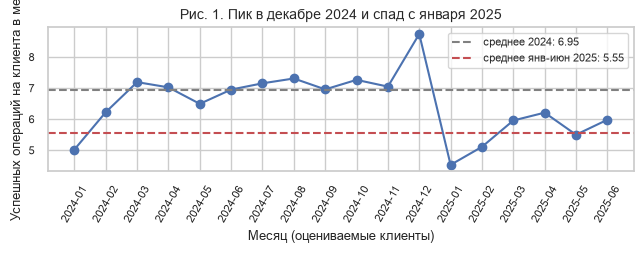

In [2]:
mon = tcoh.groupby("ym").size() / len(coh)
fig, ax = plt.subplots()
ax.plot(mon.index.astype(str), mon.values, marker="o", color="#4C72B0")
ax.axhline(coh.b_m.mean(), color="gray", ls="--", label="среднее 2024: %.2f" % coh.b_m.mean())
ax.axhline(coh.e_m.mean(), color="#C44E52", ls="--", label="среднее янв-июн 2025: %.2f" % coh.e_m.mean())
ax.set_ylabel("Успешных операций на клиента в месяц"); ax.set_xlabel("Месяц (оцениваемые клиенты)"); ax.tick_params(axis="x", rotation=60); ax.legend()
ax.set_title("Рис. 1. Пик в декабре 2024 и спад с января 2025"); plt.tight_layout(); plt.show()

Декабрь 2024 дает +26% к среднему 2024 года, январь слабее; если сравнить январь–июнь с январем–июнем прошлого года, падение 14,4%, а не 20,2%. Отдельно видна потеря, которую метрика по действующим клиентам не видит: **359 клиентов с операциями в 2024 году отсутствуют в справочнике** — это 6,5% операций 2024 года; последние операции у них приходятся на 2024-10–2025-03. Мы считаем их ушедшими из банка.

### 4.2. Массовый сегмент без приложения погас вдвое сильнее остальных

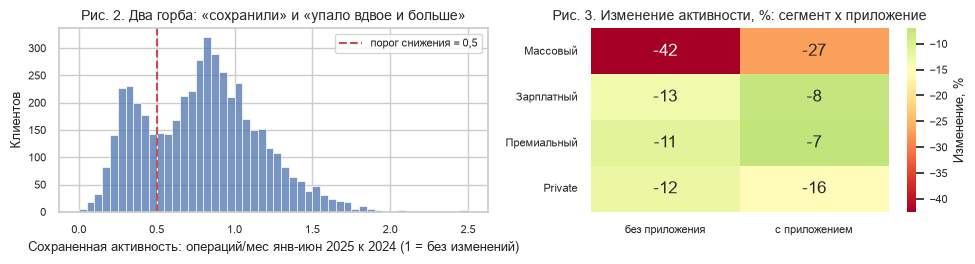

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8), gridspec_kw={"width_ratios": [1.15, 1]})
sns.histplot(coh.ratio.clip(upper=2.5), bins=50, color="#4C72B0", ax=ax[0]); ax[0].axvline(THR, color="#C44E52", ls="--", label="порог снижения = 0,5")
ax[0].set_xlabel("Сохраненная активность: операций/мес янв-июн 2025 к 2024 (1 = без изменений)"); ax[0].set_ylabel("Клиентов"); ax[0].legend(); ax[0].set_title("Рис. 2. Два горба: «сохранили» и «упало вдвое и больше»")
hm = coh.assign(app=np.where(coh.has_mobile_app, "с приложением", "без приложения")).groupby(["segment", "app"]).agg(n=("b_m", "size"), b=("b_m", "mean"), e=("e_m", "mean"))
hm["chg"] = (hm.e / hm.b - 1) * 100
order = ["Массовый", "Зарплатный", "Премиальный", "Private"]
piv = hm["chg"].unstack("app").loc[order]; sns.heatmap(piv, annot=True, fmt=".0f", cmap="RdYlGn", center=-15, cbar_kws={"label": "Изменение, %"}, ax=ax[1])
ax[1].set_title("Рис. 3. Изменение активности, %: сегмент x приложение"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

Распределение двугорбое: клиенты либо сохраняют активность (медиана 0,9 от базы — это сезонный фон), либо теряют ее примерно на две трети (медианное сохранение 0,33 в январе–марте и 0,26 в апреле–июне - активность продолжает гаснуть). По чистой случайности при ~7 операциях в месяц порог 0,5 «поймал» бы около 1% клиентов, а поймал 27% - это реальное явление. В Массовом сегменте активность упала на 32,8% (Зарплатный 9,6%, Премиальный 8,4%, Private 14,8%); без приложения - 42,5% против 27,1% с приложением (n = 1 012 и 1 570).

### 4.3. Удержавшиеся клиенты сменили способ оплаты, а не отказались от карты

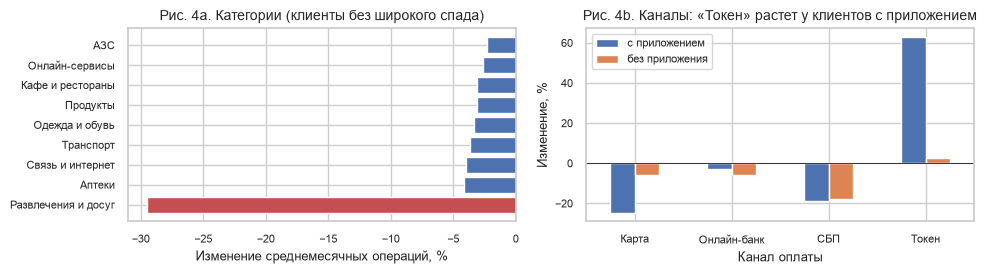

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 2.9))
c = per_chg(x_nd, "category").sort_values(); ax[0].barh(c.index, c.values, color=["#C44E52" if v < -20 else "#4C72B0" for v in c.values])
ax[0].set_xlabel("Изменение среднемесячных операций, %"); ax[0].set_title("Рис. 4a. Категории (клиенты без широкого спада)")
w = pd.DataFrame({"с приложением": per_chg(x_nd[x_nd.client_id.isin(app_ids)], "channel"), "без приложения": per_chg(x_nd[~x_nd.client_id.isin(app_ids)], "channel")})
w.plot.bar(ax=ax[1], rot=0, color=["#4C72B0", "#DD8452"]); ax[1].axhline(0, color="k", lw=0.6); ax[1].set_ylabel("Изменение, %"); ax[1].set_xlabel("Канал оплаты"); ax[1].set_title("Рис. 4b. Каналы: «Токен» растет у клиентов с приложением")
plt.tight_layout(); plt.show()

Среди 3 554 клиентов без широкого спада активность изменилась на −5,8%. Во всех категориях, кроме «Развлечения и досуг», изменение лежит между −4,1% и −2,4%; «Развлечения и досуг» - −29,5%. У клиентов с приложением «Карта» −25%, «СБП» −19%, «Токен» +63%: доля токена в операциях выросла с 17% до 30%. У клиентов без приложения «Токен» не растет (+3%). Это перенос способа оплаты, а не отказ от карты.

### 4.4. 359 клиентов ушли из банка, и ни одна метрика по справочнику их не видит

В 2024 году в среднем около 351 клиентов в месяц; к декабрю 2024 активных осталось 247, к марту 2025 - 54. Это постепенный уход, который в данных справочника действующих клиентов невиден; кампания по ним невозможна (нет атрибутов и согласия), но их оттоку нужен отдельный разбор.

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

In [11]:
GT = pd.DataFrame([
 ("G1", "Массовый сегмент, без мобильного приложения; активность упала более чем вдвое (не более 50% от базы) по всем категориям и каналам", 488,
  "Активность гаснет: −68,1% в среднем, 22% базы к апрелю–июню; падение −72…−67% по всем девяти категориям и −73…−67% по всем каналам — не смена канала и не одна категория."),
 ("G2", "Массовый сегмент, с приложением; активность упала более чем вдвое по всем категориям и каналам", 439,
  "−66,8% в среднем, 28% базы к апрелю–июню; «Токен» тоже −66%: клиенты с приложением, но карта перестала быть основной."),
 ("G3", "Зарплатный, Премиальный, Private; активность упала более чем вдвое по всем категориям и каналам", 223,
  "−65,4% в среднем, 30% базы к апрелю–июню; более ценные клиенты (медианный доход 97 800 руб/мес, 52% с приложением); падение так же равномерно по категориям."),
 ("G4", "Любой сегмент; общая активность сохранилась (падение не более чем вдвое), но в 2024 было ≥12 операций в «Развлечения и досуг», а в январе–июне 2025 — не больше 1", 220,
  "Избирательный уход из одной категории: «Развлечения и досуг» −96%, общая активность −27,5%, остальные категории в основном держатся."),
], columns=["Группа", "Правило отбора (кто + что произошло)", "Размер, клиентов", "Причина падения (по данным)"])
pd.set_option("display.max_colwidth", None)
display(HTML(GT.to_html(index=False, escape=False)))

Группа,Правило отбора (кто + что произошло),"Размер, клиентов",Причина падения (по данным)
G1,"Массовый сегмент, без мобильного приложения; активность упала более чем вдвое (не более 50% от базы) по всем категориям и каналам",488,"Активность гаснет: −68,1% в среднем, 22% базы к апрелю–июню; падение −72…−67% по всем девяти категориям и −73…−67% по всем каналам — не смена канала и не одна категория."
G2,"Массовый сегмент, с приложением; активность упала более чем вдвое по всем категориям и каналам",439,"−66,8% в среднем, 28% базы к апрелю–июню; «Токен» тоже −66%: клиенты с приложением, но карта перестала быть основной."
G3,"Зарплатный, Премиальный, Private; активность упала более чем вдвое по всем категориям и каналам",223,"−65,4% в среднем, 30% базы к апрелю–июню; более ценные клиенты (медианный доход 97 800 руб/мес, 52% с приложением); падение так же равномерно по категориям."
G4,"Любой сегмент; общая активность сохранилась (падение не более чем вдвое), но в 2024 было ≥12 операций в «Развлечения и досуг», а в январе–июне 2025 — не больше 1",220,"Избирательный уход из одной категории: «Развлечения и досуг» −96%, общая активность −27,5%, остальные категории в основном держатся."


Размеры — клиенты **с согласием на маркетинг** (без этого условия подходили бы 547, 484, 256 и 252). Группы не пересекаются **по построению**: G1–G3 требуют широкого спада и делятся по сегменту и приложению, G4 требует его отсутствия; если бы клиент подходил под несколько правил, приоритет — по масштабу падения G1 → G2 → G3 → G4. Каждое правило считается по двум таблицам: сегмент, наличие приложения, число операций по месяцам, категории, согласие на маркетинг - так что новый клиент из новой выгрузки классифицируется однозначно.

**G1 (Массовый, без приложения).** Самая большая и самая быстро гаснущая группа: к апрелю–июню остается 22% базы. Падение одинаково по всем категориям и каналам, значит это не «ушли с одной услуги»; вероятная гипотеза - карта перестала быть основной (в данных это не проверяется). Приложения нет - коммуникация через офлайн-каналы, SMS и банкоматы; цель - вернуть карту как основную в быту (по банку самая частая категория - «Продукты»).

**G2 (Массовый, с приложением).** Тот же характер падения при наличии приложения: активность через токен тоже упала (−66%). Приложение есть, поэтому возможна цифровая коммуникация (push, предложения в приложении); предложение - привязать карту к токену и вернуть регулярные платежи.

**G3 (Зарплатный, Премиальный, Private).** Более ценные клиенты: до падения 7,4 операции в месяц, сейчас 2,6. Падение равномерное, как у G1–G2, но активность на клиента выше; уместна персональная коммуникация менеджером.

**G4 (ушли из «Развлечения и досуг»).** Единственная группа с узким и понятным предложением: клиент продолжает пользоваться картой (78% базы к апрелю–июню), но почти перестал платить за развлечения (−96%). Предложение — категорийный кэшбэк или партнерские скидки. Оценка чистоты: если бы поведение не менялось, по чистой случайности под правило попало бы около 10 клиентов из 252, то есть не более 4%.

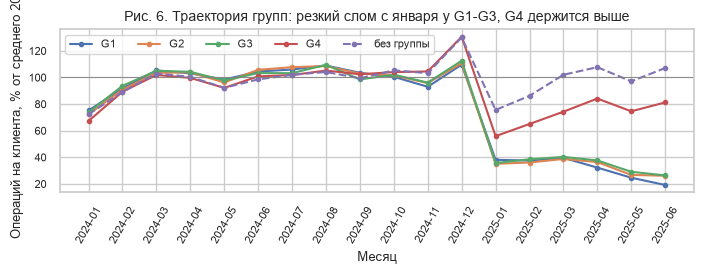

In [7]:
mon_g = {}
for g in ["G1", "G2", "G3", "G4"]:
    ids = coh.client_id[coh.group == g]; s = tcoh[tcoh.client_id.isin(ids)].groupby("ym").size() / len(ids); mon_g[g] = s / s["2024-01":"2024-12"].mean() * 100
ids = coh.client_id[coh.group_all == ""]; s = tcoh[tcoh.client_id.isin(ids)].groupby("ym").size() / len(ids); mon_g["без группы"] = s / s["2024-01":"2024-12"].mean() * 100
fig, ax = plt.subplots(figsize=(7.2, 2.9))
for g, s in mon_g.items(): ax.plot(s.index.astype(str), s.values, marker="o", ms=3, label=g, ls="--" if g == "без группы" else "-")
ax.axhline(100, color="gray", lw=0.6); ax.set_ylabel("Операций на клиента, % от среднего 2024"); ax.set_xlabel("Месяц"); ax.tick_params(axis="x", rotation=60); ax.legend(ncol=5)
ax.set_title("Рис. 6. Траектория групп: резкий слом с января у G1-G3, G4 держится выше"); plt.tight_layout(); plt.show()

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

In [8]:
EX = pd.DataFrame([
 ("Ушли из банка (операции есть, в справочнике нет)", 359, "нет атрибутов и согласия, кампанией по действующим клиентам не достижимы; нужен отдельный разбор оттока"),
 ("Конфликт записей client_id (разные сегмент/город)", 15, "сегмент входит в правила групп, а какая запись верна - неизвестно; сначала сверка с источником"),
 ("Карта открыта в 2024 году", 456, "нет полных 12 месяцев базы - падение не оценить; рост активности новой карты - не падение"),
 ("Карта открыта в 2025 году (7 без операций вообще)", 329, "нет базового периода - снижение не определено"),
 ("Подходят под правило группы, но без согласия на маркетинг", 168, "коммуникация без согласия невозможна"),
 ("Без снижения и без ухода из развлечений", 3302, "активность в норме (с поправкой на сезонность); кампания им не нужна, риск раздражить"),
], columns=["Кто", "Клиентов", "Почему кампания не нужна или бесполезна"])
display(HTML(EX.to_html(index=False)))

Кто,Клиентов,Почему кампания не нужна или бесполезна
"Ушли из банка (операции есть, в справочнике нет)",359,"нет атрибутов и согласия, кампанией по действующим клиентам не достижимы; нужен отдельный разбор оттока"
Конфликт записей client_id (разные сегмент/город),15,"сегмент входит в правила групп, а какая запись верна - неизвестно; сначала сверка с источником"
Карта открыта в 2024 году,456,нет полных 12 месяцев базы - падение не оценить; рост активности новой карты - не падение
Карта открыта в 2025 году (7 без операций вообще),329,нет базового периода - снижение не определено
"Подходят под правило группы, но без согласия на маркетинг",168,коммуникация без согласия невозможна
Без снижения и без ухода из развлечений,3302,"активность в норме (с поправкой на сезонность); кампания им не нужна, риск раздражить"


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

In [9]:
HY = pd.DataFrame([
 ("«Зарплата в нашем банке» стабильнее", "не подтвердилось внутри сегмента", "−15,2% (n=2122) против −24,5% (n=2719); внутри Массового −33,0% против −32,7%"),
 ("Новосибирск просел сильнее", "не подтвердилось: эффект состава", "−29,6% (n=826) против −18,5% (n=4015), но 89% клиентов там Массовые; внутри Массового −33,6% против −32,4%"),
 ("Недовольные (оценка 1–2) снизили активность сильнее", "не подтвердилось", "−20,4% (n=627) против −16,9% (n=987) у оценок 4–5; внутри Массового −31,0% против −32,0%; ответили 41% клиентов"),
 ("Давно не заходившие в приложение снизили сильнее", "не подтвердилось", "вход в 2025: −16,5% (n=964); последний вход раньше: −16,6% (n=2009)"),
 ("Согласие на маркетинг связано с падением", "не подтвердилось", "с согласием −20,3% (n=4268), без согласия −19,0% (n=573)"),
], columns=["Гипотеза", "Итог", "Числа: изменение среднемесячных операций, n клиентов"])
display(HTML(HY.to_html(index=False)))

Гипотеза,Итог,"Числа: изменение среднемесячных операций, n клиентов"
«Зарплата в нашем банке» стабильнее,не подтвердилось внутри сегмента,"−15,2% (n=2122) против −24,5% (n=2719); внутри Массового −33,0% против −32,7%"
Новосибирск просел сильнее,не подтвердилось: эффект состава,"−29,6% (n=826) против −18,5% (n=4015), но 89% клиентов там Массовые; внутри Массового −33,6% против −32,4%"
Недовольные (оценка 1–2) снизили активность сильнее,не подтвердилось,"−20,4% (n=627) против −16,9% (n=987) у оценок 4–5; внутри Массового −31,0% против −32,0%; ответили 41% клиентов"
Давно не заходившие в приложение снизили сильнее,не подтвердилось,"вход в 2025: −16,5% (n=964); последний вход раньше: −16,6% (n=2009)"
Согласие на маркетинг связано с падением,не подтвердилось,"с согласием −20,3% (n=4268), без согласия −19,0% (n=573)"


## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

In [10]:
lg_ = pd.read_csv("../cleaning_log.csv")
cols = ["field", "issue", "n_rows", "action", "rationale"]
display(HTML(lg_[cols].head(5).to_html(index=False)))

field,issue,n_rows,action,rationale
amount,"десятичный разделитель ','",628510,исправлено,без приведения суммы не агрегируются
registration_date,дата хранится строкой в формате DD.MM.YYYY,5696,исправлено,без datetime64 не считается стаж и не работают сравнения с окнами периода; '%d.%m.%Y' задан явно — иначе авто-парсер для '03.04.2024' берет month-first и молча дает 3 апреля вместо 4 марта
card_open_date,дата хранится строкой в формате DD.MM.YYYY,5696,исправлено,без datetime64 не считается стаж и не работают сравнения с окнами периода; '%d.%m.%Y' задан явно — иначе авто-парсер для '03.04.2024' берет month-first и молча дает 3 апреля вместо 4 марта
app_last_login,месяц последнего входа ('YYYY-MM') без дня; при переводе в дату день восстановлен как 01,3547,исправлено,день из источника не известен; для сравнения с окнами периода достаточно месяца — 1-е число трактуем как начало месяца
satisfaction_score,порядковая шкала 1..5 хранится как object,2341,исправлено,числовой тип нужен для описательных статистик; сами значения шкалы не меняются


### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->

- **Чтение:** кодировка, разделитель и десятичный знак определены кодом (clients — utf-8-sig, «,», точка; transactions — cp1251, «;», запятая).
- **Дубли:** полные дубли строк удалены; из пар с одинаковым `txn_id` оставлена запись со временем (сортировка по `txn_id`, наличию времени).
- **Фильтры активности:** `status = успешно`; дата в [2024-01-01; 2025-06-30]; клиент есть в справочнике; клиент оцениваем (`card_open_date < 2024-01-01`, нет конфликта id). EUR/USD остаются в счётчике, исключены из денежных расчётов.
- **Метрика:** `b_m = N_2024 / 12`, `e_m = N_(2025-01…06) / 6`, `ratio = e_m / b_m`, изменение = `ratio − 1`; групповое изменение = (среднее `e_m` / среднее `b_m`) − 1.
- **Снижение (широкий спад):** `ratio ≤ 0,5`. Чувствительность: порог 0,4 / 0,5 / 0,6 даёт 950 / 1 287 / 1 543 клиентов.
- **Группы:** G1 = широкий спад ∧ Массовый ∧ без приложения; G2 = широкий спад ∧ Массовый ∧ с приложением; G3 = широкий спад ∧ не Массовый; G4 = ¬широкий спад ∧ (операций в «Развлечения и досуг» в 2024 ≥ 12) ∧ (в янв–июн 2025 ≤ 1); во всех — `marketing_opt_in = Да`.
- **Выбросы:** обнаружение — правило Тьюки (линейная интерполяция квантилей, 1,5 МКР), три сигмы, робастная z, бизнес-границы; решение отдельно (журнал). Суммы не влияют на метрику (число операций).
- **Случайность:** `seed = 42`.
- **Ограничения метода:** индивидуальная оценка при ~7 операциях в месяц шумная (~19% относительной ошибки), поэтому выводы делаются на уровне групп; разведочные находки не проверены на независимых данных.

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->

ИИ (Claude) применён для черновиков кода чтения и очистки данных, построения графиков и групповых сравнений в обоих ноутбуках, а также для черновика текста отчёта и подбора формулировок выводов по уже посчитанным числам.

Сама: проверила все числа в тексте отчёта сверены с выводом кода; выбрала порог снижения по провалу между двумя горбами распределения, правило приоритета групп G1 → G2 → G3 → G4; приняла решения по дублям, выбросам и исключениям; выбрала метрику.